Hemos cargado los archivos en el teachable machine las muestras de los dos tipos; y hemos hecho una prueba de que funciona

# 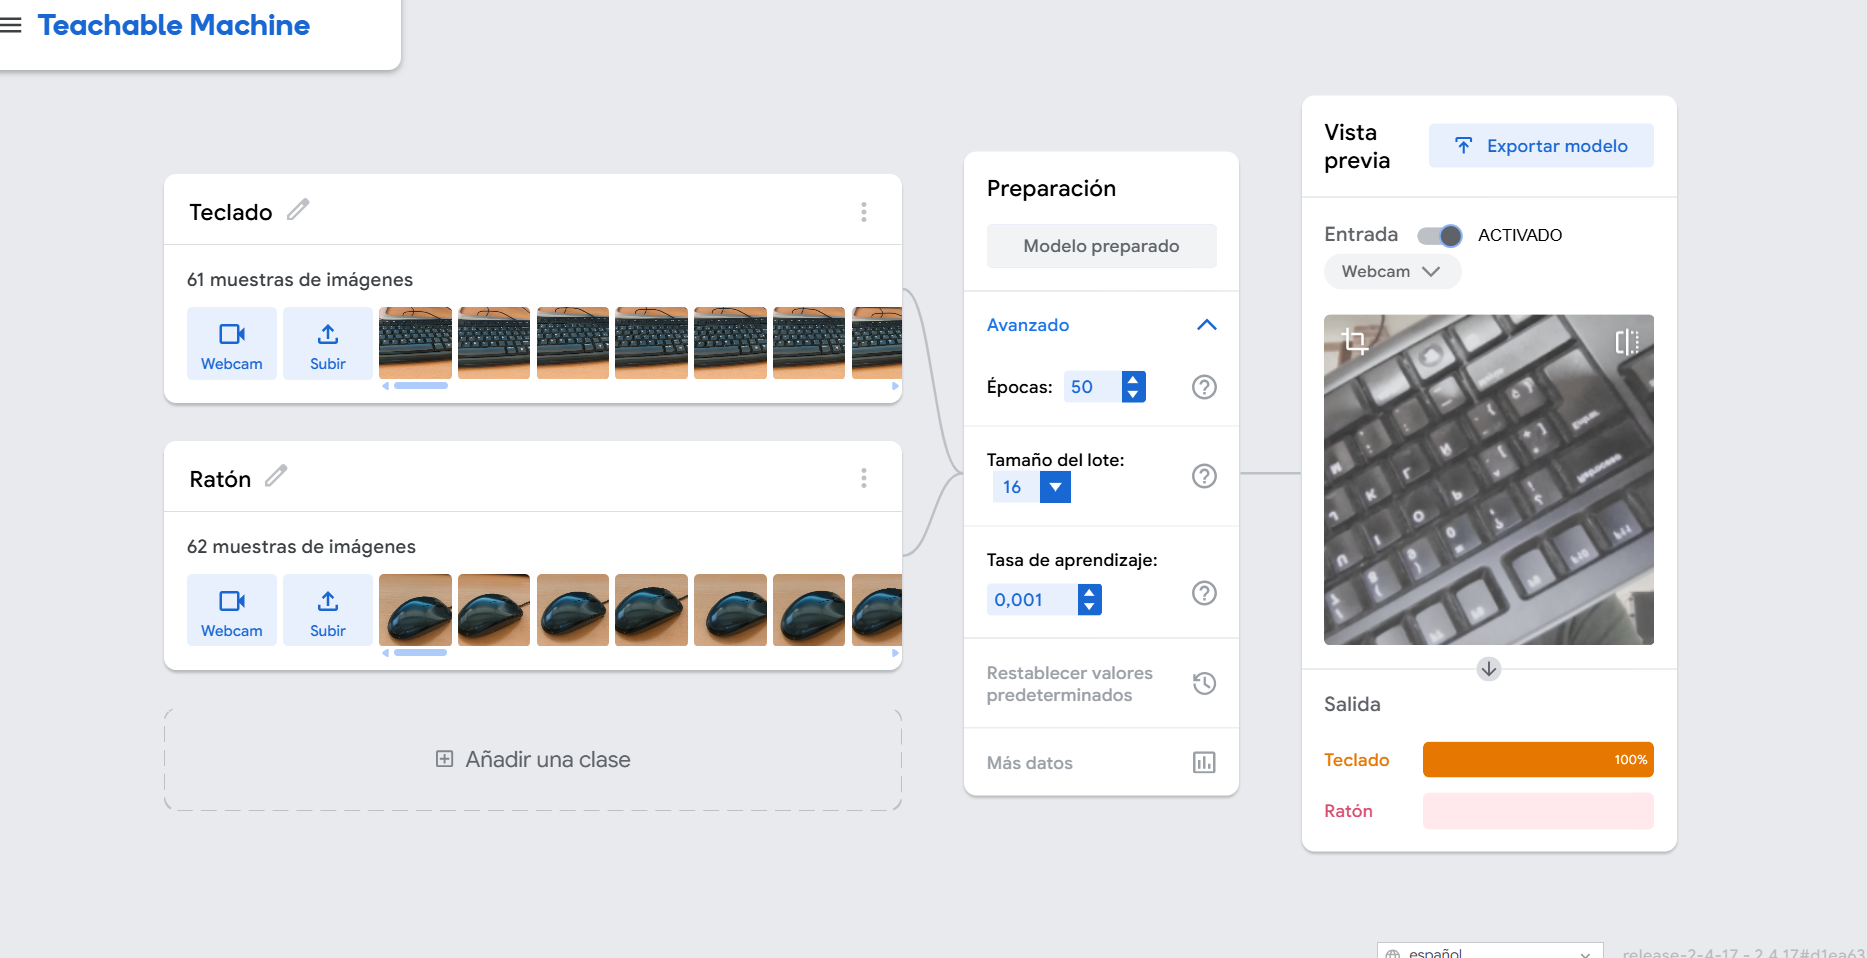

Exportamos el modelo en TensorFlow.js para poder usarlas en visual

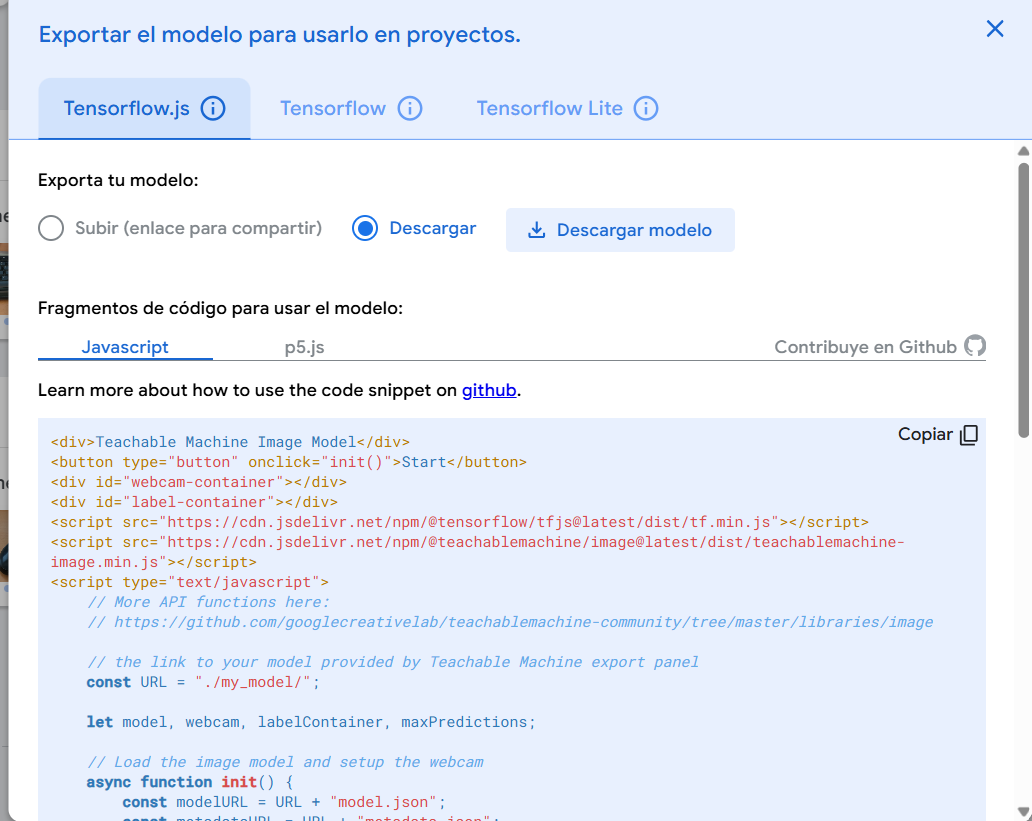

Ahora en Visual llevamos los archivos y creamos tal nos pide la tarea

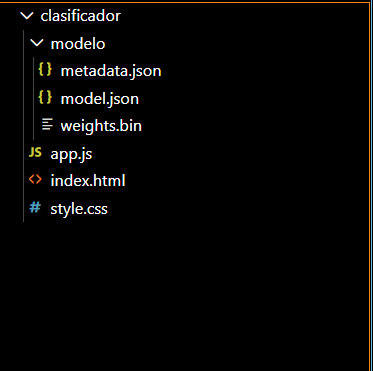

Este es el código del index:


In [ ]:
<!DOCTYPE html>
<html lang="es">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>¿Teclado o ratón?</title>
  <link rel="preconnect" href="https://fonts.googleapis.com">
  <link rel="preconnect" href="https://fonts.gstatic.com" crossorigin>
  <link href="https://fonts.googleapis.com/css2?family=Bricolage+Grotesque:wght@600;800&family=IBM+Plex+Sans:wght@400;500;600&display=swap" rel="stylesheet">
  <link rel="stylesheet" href="style.css">
</head>
<body>
  <header class="cabecera">
    <h1>¿Teclado o ratón?</h1>
    <p>Enseña un objeto a la cámara o sube una foto y el modelo te dirá cuál es.</p>
  </header>

  <main class="rejilla">
    <!-- Columna izquierda: cámara -->
    <section class="tarjeta camara" aria-labelledby="titulo-camara">
      <h2 id="titulo-camara">Cámara en directo</h2>

      <div class="visor" id="visor" data-estado="inactivo">
        <span class="esquina sup-izq"></span>
        <span class="esquina sup-der"></span>
        <span class="esquina inf-izq"></span>
        <span class="esquina inf-der"></span>
        <div id="webcam-container" class="visor-imagen"></div>
        <p class="visor-vacio" id="visorVacio">La cámara está apagada</p>
      </div>

      <div class="lectura" aria-live="polite">
        <p class="lectura-titulo" id="lecturaTitulo">Pulsa «Iniciar» para empezar</p>
        <p class="lectura-detalle" id="lecturaDetalle"></p>
      </div>

      <div class="botones">
        <button type="button" class="boton primario" id="btnIniciar">Iniciar</button>
        <button type="button" class="boton secundario" id="btnParar" disabled>Parar</button>
      </div>

      <p class="estado" id="estado" role="status">Modelo sin cargar</p>

      <div class="mensaje-salida" id="mensajeSalida" role="status" hidden></div>
    </section>

    <!-- Columna derecha: ajustes, resultados, imagen e histórico -->
    <div class="columna">
      <section class="tarjeta" aria-labelledby="titulo-resultados">
        <h2 id="titulo-resultados">Resultados</h2>
        <div class="barras" id="barras" aria-live="off"></div>

        <div class="umbral">
          <label for="umbral">Valor mínimo para considerarlo coincidencia</label>
          <div class="umbral-control">
            <input type="range" id="umbral" min="50" max="100" step="1" value="80">
            <output id="umbralValor" for="umbral">80 %</output>
          </div>
        </div>
      </section>

      <section class="tarjeta" aria-labelledby="titulo-imagen">
        <h2 id="titulo-imagen">Calificar una imagen</h2>
        <label class="subida" for="archivo">
          <span>Elegir una imagen del equipo</span>
          <input type="file" id="archivo" accept="image/*">
        </label>
        <div class="subida-resultado" id="subidaResultado" hidden>
          <img id="vistaPrevia" alt="Imagen subida para clasificar">
          <div>
            <p class="veredicto" id="veredicto"></p>
            <div class="barras" id="barrasImagen"></div>
          </div>
        </div>
      </section>

      <section class="tarjeta" aria-labelledby="titulo-historico">
        <div class="tarjeta-cabecera">
          <h2 id="titulo-historico">Histórico</h2>
          <button type="button" class="boton texto" id="btnBorrar">Borrar histórico</button>
        </div>
        <ul class="historico" id="historico"></ul>
        <p class="historico-vacio" id="historicoVacio">Todavía no hay resultados. Inicia la cámara o sube una imagen.</p>
      </section>
    </div>
  </main>

  <script src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@1.7.4/dist/tf.min.js"></script>
  <script src="https://cdn.jsdelivr.net/npm/@teachablemachine/image@0.8/dist/teachablemachine-image.min.js"></script>
  <script src="app.js"></script>
</body>
</html>


Este es el de los estilos:


In [ ]:
:root {
  --fondo: #e8edf1;
  --tarjeta: #ffffff;
  --tinta: #14212b;
  --tinta-suave: #54636f;
  --linea: #d3dbe2;
  --acento: #2f5bff;
  --acento-oscuro: #1e3fc4;
  --acierto: #12805c;
  --fallo: #b7791f;
  --radio: 14px;
}

* { box-sizing: border-box; }

body {
  margin: 0;
  padding: clamp(16px, 4vw, 40px);
  background: var(--fondo);
  color: var(--tinta);
  font-family: "IBM Plex Sans", system-ui, -apple-system, "Segoe UI", sans-serif;
  line-height: 1.5;
}

h1, h2 {
  font-family: "Bricolage Grotesque", "IBM Plex Sans", system-ui, sans-serif;
  margin: 0;
  line-height: 1.1;
}

h1 { font-size: clamp(2.2rem, 7vw, 4rem); font-weight: 800; letter-spacing: -0.02em; }
h2 { font-size: 1.25rem; font-weight: 600; }

.cabecera { max-width: 1100px; margin: 0 auto 28px; }
.cabecera p { margin: 10px 0 0; color: var(--tinta-suave); font-size: 1.05rem; max-width: 52ch; }


.rejilla {
  max-width: 1100px;
  margin: 0 auto;
  display: grid;
  grid-template-columns: 1fr;
  gap: 20px;
  align-items: start;
}

.columna { display: grid; gap: 20px; }

@media (min-width: 900px) {
  .rejilla { grid-template-columns: minmax(340px, 1fr) minmax(340px, 1fr); }
  .camara { position: sticky; top: 24px; }
}

.tarjeta {
  background: var(--tarjeta);
  border: 1px solid var(--linea);
  border-radius: var(--radio);
  padding: clamp(16px, 3vw, 24px);
  display: grid;
  gap: 16px;
}

.tarjeta-cabecera { display: flex; justify-content: space-between; align-items: center; gap: 12px; }


.visor {
  position: relative;
  width: 100%;
  max-width: 420px;
  aspect-ratio: 1 / 1;
  margin: 0 auto;
  background: #0f1a22;
  border-radius: 10px;
  overflow: hidden;
  --marco: #8696a3;
}

.visor-imagen, .visor-imagen canvas {
  position: absolute;
  inset: 0;
  width: 100%;
  height: 100%;
}

.visor-vacio {
  position: absolute;
  inset: 0;
  display: grid;
  place-items: center;
  margin: 0;
  color: #9fb0bd;
  font-size: 0.95rem;
}

.visor:not([data-estado="inactivo"]) .visor-vacio { display: none; }

.esquina {
  position: absolute;
  width: 34px;
  height: 34px;
  border: 4px solid var(--marco);
  z-index: 2;
  transition: border-color 0.2s;
}
.sup-izq { top: 12px; left: 12px; border-right: 0; border-bottom: 0; border-top-left-radius: 8px; }
.sup-der { top: 12px; right: 12px; border-left: 0; border-bottom: 0; border-top-right-radius: 8px; }
.inf-izq { bottom: 12px; left: 12px; border-right: 0; border-top: 0; border-bottom-left-radius: 8px; }
.inf-der { bottom: 12px; right: 12px; border-left: 0; border-top: 0; border-bottom-right-radius: 8px; }

.visor[data-estado="buscando"] { --marco: #ffffff; }
.visor[data-estado="coincide"] { --marco: #3ddc97; }
.visor[data-estado="sin-coincidencia"] { --marco: #f0b44c; }


.lectura { text-align: center; min-height: 4.2rem; }
.lectura-titulo {
  margin: 0;
  font-family: "Bricolage Grotesque", sans-serif;
  font-weight: 800;
  font-size: clamp(1.7rem, 6vw, 2.4rem);
  line-height: 1.1;
}
.lectura-detalle { margin: 6px 0 0; color: var(--tinta-suave); }
.lectura.coincide .lectura-titulo { color: var(--acierto); }
.lectura.sin-coincidencia .lectura-titulo { color: var(--fallo); }


.botones { display: flex; gap: 12px; }

.boton {
  font: inherit;
  font-weight: 600;
  min-height: 48px;
  padding: 0 22px;
  border-radius: 10px;
  border: 2px solid transparent;
  cursor: pointer;
  transition: background 0.15s, border-color 0.15s, color 0.15s;
}
.botones .boton { flex: 1; }

.boton.primario { background: var(--acento); color: #fff; }
.boton.primario:hover:not(:disabled) { background: var(--acento-oscuro); }

.boton.secundario { background: transparent; color: var(--tinta); border-color: var(--tinta); }
.boton.secundario:hover:not(:disabled) { background: var(--tinta); color: #fff; }

.boton.texto { min-height: 36px; padding: 0 10px; background: transparent; color: var(--tinta-suave); text-decoration: underline; }
.boton.texto:hover { color: var(--tinta); }

.boton:disabled { opacity: 0.4; cursor: not-allowed; }

:focus-visible { outline: 3px solid var(--acento); outline-offset: 2px; }

.estado { margin: 0; text-align: center; font-size: 0.9rem; color: var(--tinta-suave); }

.mensaje-salida {
  padding: 14px 16px;
  border-radius: 10px;
  background: #eaf1ff;
  border-left: 5px solid var(--acento);
}


.barras { display: grid; gap: 12px; --umbral: 80%; }

.barra-fila { display: grid; grid-template-columns: 110px 1fr 52px; align-items: center; gap: 10px; }
.barra-nombre { font-weight: 600; }
.barra-valor { text-align: right; font-variant-numeric: tabular-nums; color: var(--tinta-suave); }

.barra-pista {
  position: relative;
  height: 14px;
  background: #e6ebef;
  border-radius: 7px;
  overflow: hidden;
}
.barra-relleno {
  height: 100%;
  width: 0;
  background: #9fb0bd;
  border-radius: 7px;
  transition: width 0.15s linear, background 0.15s;
}
.barra-fila.supera .barra-relleno { background: var(--acierto); }
.barra-pista::after {
  content: "";
  position: absolute;
  top: 0;
  bottom: 0;
  left: var(--umbral);
  width: 2px;
  background: var(--tinta);
}


.umbral { display: grid; gap: 8px; padding-top: 14px; border-top: 1px solid var(--linea); }
.umbral label { font-weight: 500; }
.umbral-control { display: flex; align-items: center; gap: 14px; }
.umbral-control input { flex: 1; accent-color: var(--acento); height: 32px; }
.umbral-control output { min-width: 3.4em; text-align: right; font-weight: 600; font-variant-numeric: tabular-nums; }


.subida {
  display: grid;
  place-items: center;
  min-height: 84px;
  padding: 12px;
  border: 2px dashed var(--tinta-suave);
  border-radius: 10px;
  cursor: pointer;
  text-align: center;
  font-weight: 500;
}
.subida:hover, .subida:focus-within { background: #f2f6ff; border-color: var(--acento); }
.subida input { max-width: 100%; margin-top: 8px; font: inherit; font-size: 0.85rem; }

.subida-resultado { display: grid; grid-template-columns: 140px 1fr; gap: 16px; align-items: start; }
.subida-resultado[hidden] { display: none; }
.subida-resultado img { width: 100%; aspect-ratio: 1 / 1; object-fit: cover; border-radius: 10px; background: #e6ebef; }
.veredicto { margin: 0 0 10px; font-weight: 600; }
.veredicto.coincide { color: var(--acierto); }
.veredicto.sin-coincidencia { color: var(--fallo); }

.historico { list-style: none; margin: 0; padding: 0; max-height: 340px; overflow-y: auto; }
.historico li {
  display: grid;
  grid-template-columns: 1fr auto;
  gap: 2px 12px;
  padding: 10px 0;
  border-bottom: 1px solid var(--linea);
}
.historico li:last-child { border-bottom: 0; }
.hist-resultado { font-weight: 600; }
.hist-resultado.coincide { color: var(--acierto); }
.hist-resultado.sin-coincidencia { color: var(--fallo); }
.hist-prob { font-variant-numeric: tabular-nums; font-weight: 600; text-align: right; }
.hist-meta { grid-column: 1 / -1; font-size: 0.85rem; color: var(--tinta-suave); overflow-wrap: anywhere; }
.historico-vacio { margin: 0; color: var(--tinta-suave); }

@media (max-width: 520px) {
  .barra-fila { grid-template-columns: 84px 1fr 48px; gap: 8px; }
  .subida-resultado { grid-template-columns: 1fr; }
  .subida-resultado img { max-width: 220px; }
}

@media (prefers-reduced-motion: reduce) {
  * { transition: none !important; }
}


Y este mi app.js que explicare abajo:

In [ ]:

const MODEL_URL = "./modelo/model.json";
const METADATA_URL = "./modelo/metadata.json";

const HISTORY_KEY = "tm-historico";
const THRESHOLD_KEY = "tm-umbral";
const MAX_HISTORY = 50;
const REPEAT_MS = 5000;

const ICONS = { "Teclado": "⌨️", "Ratón": "🖱️" };

let model = null;
let webcam = null;
let rafId = null;
let running = false;

let lastMatchLabel = null;
let lastRecordTime = 0;
let sessionCounts = {};
let history = loadHistory();

const $ = (id) => document.getElementById(id);
const el = {
  visor: $("visor"),
  webcamContainer: $("webcam-container"),
  lectura: document.querySelector(".lectura"),
  lecturaTitulo: $("lecturaTitulo"),
  lecturaDetalle: $("lecturaDetalle"),
  btnIniciar: $("btnIniciar"),
  btnParar: $("btnParar"),
  estado: $("estado"),
  mensajeSalida: $("mensajeSalida"),
  barras: $("barras"),
  umbral: $("umbral"),
  umbralValor: $("umbralValor"),
  archivo: $("archivo"),
  subidaResultado: $("subidaResultado"),
  vistaPrevia: $("vistaPrevia"),
  veredicto: $("veredicto"),
  barrasImagen: $("barrasImagen"),
  historico: $("historico"),
  historicoVacio: $("historicoVacio"),
  btnBorrar: $("btnBorrar"),
};



function icon(label) {
  return ICONS[label] ? ICONS[label] + " " : "";
}

function pct(p) {
  return Math.round(p * 100);
}

function getThreshold() {
  return Number(el.umbral.value) / 100;
}

function setStatus(text) {
  el.estado.textContent = text;
}

function bestOf(predictions) {
  return predictions.reduce((a, b) => (b.probability > a.probability ? b : a));
}



async function ensureModel() {
  if (model) return model;
  setStatus("Cargando modelo…");
  try {
    model = await tmImage.load(MODEL_URL, METADATA_URL);
  } catch (err) {
    console.error(err);
    if (location.protocol === "file:") {
      setStatus("No se pudo cargar el modelo: la página está abierta como archivo (file://). Ábrela con Live Server en VS Code.");
    } else {
      setStatus("No se pudo cargar el modelo (" + (err && err.message ? err.message : err) +
        "). Comprueba que model.json, weights.bin y metadata.json están en la misma carpeta que index.html.");
    }
    throw err;
  }
  setStatus("Modelo cargado");
  return model;
}



function renderBars(container, predictions) {
  if (container.children.length !== predictions.length) {
    container.replaceChildren();
    predictions.forEach(() => {
      const row = document.createElement("div");
      row.className = "barra-fila";
      row.innerHTML =
        '<span class="barra-nombre"></span>' +
        '<div class="barra-pista"><div class="barra-relleno"></div></div>' +
        '<span class="barra-valor"></span>';
      container.appendChild(row);
    });
  }
  const threshold = getThreshold();
  predictions.forEach((p, i) => {
    const row = container.children[i];
    row.querySelector(".barra-nombre").textContent = icon(p.className) + p.className;
    row.querySelector(".barra-relleno").style.width = pct(p.probability) + "%";
    row.querySelector(".barra-valor").textContent = pct(p.probability) + " %";
    row.classList.toggle("supera", p.probability >= threshold);
  });
}

function refreshThresholdUI() {
  const value = el.umbral.value;
  el.umbralValor.textContent = value + " %";
  document.querySelectorAll(".barras").forEach((c) => c.style.setProperty("--umbral", value + "%"));
}

function showReading(state, title, detail) {
  el.lectura.className = "lectura " + state;
  el.lecturaTitulo.textContent = title;
  el.lecturaDetalle.textContent = detail || "";
}



async function start() {
  if (running) return;
  el.btnIniciar.disabled = true;
  el.mensajeSalida.hidden = true;

  try {
    await ensureModel();
  } catch {
    el.btnIniciar.disabled = false;
    return;
  }

  try {
    setStatus("Activando la cámara…");
    webcam = new tmImage.Webcam(320, 320, true);
    await webcam.setup();
    await webcam.play();
  } catch (err) {
    console.error(err);
    setStatus("No se pudo usar la cámara. Revisa el permiso del navegador y que ninguna otra aplicación la esté usando.");
    el.btnIniciar.disabled = false;
    return;
  }

  el.webcamContainer.replaceChildren(webcam.canvas);
  running = true;
  sessionCounts = {};
  lastMatchLabel = null;
  lastRecordTime = 0;

  el.btnParar.disabled = false;
  el.visor.dataset.estado = "buscando";
  showReading("", "Buscando…", "Coloca un teclado o un ratón frente a la cámara");
  setStatus("Cámara activa");
  rafId = requestAnimationFrame(loop);
}

function stop() {
  if (!running) return;
  running = false;
  cancelAnimationFrame(rafId);
  webcam.stop();
  el.webcamContainer.replaceChildren();

  el.btnIniciar.disabled = false;
  el.btnParar.disabled = true;
  el.visor.dataset.estado = "inactivo";
  showReading("", "Pulsa «Iniciar» para empezar", "");
  setStatus("Cámara apagada");
  showExitMessage();
}

function showExitMessage() {
  const entries = Object.entries(sessionCounts);
  let text;
  if (entries.length === 0) {
    text = "Detección detenida. No se ha reconocido ningún objeto con un mínimo del " +
      el.umbral.value + " %. Prueba a acercarlo a la cámara o a bajar el valor mínimo.";
  } else {
    const resumen = entries.map(([label, n]) => icon(label) + label + " ×" + n).join(", ");
    text = "Detección detenida. En esta sesión has detectado: " + resumen + ". ¡Hasta la próxima!";
  }
  el.mensajeSalida.textContent = text;
  el.mensajeSalida.hidden = false;
}

async function loop() {
  if (!running) return;
  webcam.update();
  const predictions = await model.predict(webcam.canvas);
  if (!running) return;

  renderBars(el.barras, predictions);
  handleWebcamResult(predictions);
  rafId = requestAnimationFrame(loop);
}

function handleWebcamResult(predictions) {
  const best = bestOf(predictions);
  const isMatch = best.probability >= getThreshold();

  if (isMatch) {
    el.visor.dataset.estado = "coincide";
    showReading("coincide", icon(best.className) + best.className, "Seguridad: " + pct(best.probability) + " %");

    const now = Date.now();
    const isNew = best.className !== lastMatchLabel;
    if (isNew || now - lastRecordTime > REPEAT_MS) {
      addHistory({ source: "Cámara", label: best.className, prob: best.probability, match: true });
      sessionCounts[best.className] = (sessionCounts[best.className] || 0) + 1;
      lastRecordTime = now;
    }
    lastMatchLabel = best.className;
  } else {
    el.visor.dataset.estado = "sin-coincidencia";
    showReading("sin-coincidencia", "Sin coincidencia",
      "Lo más parecido: " + best.className + " (" + pct(best.probability) + " %)");
    lastMatchLabel = null;
  }
}



el.archivo.addEventListener("change", () => {
  const file = el.archivo.files[0];
  if (!file) return;

  if (!file.type.startsWith("image/")) {
    el.subidaResultado.hidden = false;
    el.veredicto.className = "veredicto sin-coincidencia";
    el.veredicto.textContent = "Ese archivo no es una imagen. Elige un JPG, PNG o WebP.";
    return;
  }

  const url = URL.createObjectURL(file);
  el.vistaPrevia.onload = async () => {
    try {
      await ensureModel();
      const predictions = await model.predict(el.vistaPrevia);
      classifyUpload(predictions, file.name);
    } catch (err) {
      el.veredicto.className = "veredicto sin-coincidencia";
      console.error(err);
      el.veredicto.textContent = "No se pudo clasificar la imagen. Mira el mensaje bajo los botones de la cámara.";
    } finally {
      URL.revokeObjectURL(url);
    }
  };
  el.vistaPrevia.src = url;
  el.subidaResultado.hidden = false;
  el.veredicto.className = "veredicto";
  el.veredicto.textContent = "Clasificando…";
  el.archivo.value = "";
});

function classifyUpload(predictions, fileName) {
  const best = bestOf(predictions);
  const isMatch = best.probability >= getThreshold();

  renderBars(el.barrasImagen, predictions);
  refreshThresholdUI();

  if (isMatch) {
    el.veredicto.className = "veredicto coincide";
    el.veredicto.textContent = "Es un " + best.className.toLowerCase() + " (" + pct(best.probability) + " %)";
  } else {
    el.veredicto.className = "veredicto sin-coincidencia";
    el.veredicto.textContent = "Sin coincidencia. Lo más parecido: " + best.className + " (" + pct(best.probability) + " %)";
  }

  addHistory({ source: "Imagen", file: fileName, label: best.className, prob: best.probability, match: isMatch });
}



function loadHistory() {
  try {
    const data = JSON.parse(localStorage.getItem(HISTORY_KEY));
    return Array.isArray(data) ? data : [];
  } catch {
    return [];
  }
}

function saveHistory() {
  try {
    localStorage.setItem(HISTORY_KEY, JSON.stringify(history));
  } catch {

  }
}

function addHistory(entry) {
  entry.time = Date.now();
  entry.threshold = Number(el.umbral.value);
  history.unshift(entry);
  history = history.slice(0, MAX_HISTORY);
  saveHistory();
  renderHistory();
}

function renderHistory() {
  el.historico.replaceChildren();
  el.historicoVacio.hidden = history.length > 0;
  el.btnBorrar.hidden = history.length === 0;

  history.forEach((h) => {
    const li = document.createElement("li");

    const result = document.createElement("span");
    result.className = "hist-resultado " + (h.match ? "coincide" : "sin-coincidencia");
    result.textContent = h.match ? icon(h.label) + h.label : "Sin coincidencia (más parecido: " + h.label + ")";

    const prob = document.createElement("span");
    prob.className = "hist-prob";
    prob.textContent = pct(h.prob) + " %";

    const meta = document.createElement("span");
    meta.className = "hist-meta";
    const date = new Date(h.time).toLocaleString("es-ES", { dateStyle: "short", timeStyle: "medium" });
    meta.textContent = h.source + (h.file ? " · " + h.file : "") + " · mínimo " + h.threshold + " % · " + date;

    li.append(result, prob, meta);
    el.historico.appendChild(li);
  });
}



el.btnIniciar.addEventListener("click", start);
el.btnParar.addEventListener("click", stop);

el.umbral.addEventListener("input", () => {
  refreshThresholdUI();
  try { localStorage.setItem(THRESHOLD_KEY, el.umbral.value); } catch { /* sin almacenamiento */ }
});

el.btnBorrar.addEventListener("click", () => {
  history = [];
  saveHistory();
  renderHistory();
});


try {
  const saved = localStorage.getItem(THRESHOLD_KEY);
  if (saved) el.umbral.value = saved;
} catch {

}

refreshThresholdUI();
renderHistory();


Este código es la parte de JavaScript que hace funcionar una página web para reconocer si enseñas a la cámara un teclado o un ratón. Lo que hace exactamente es cargar primero los archivos donde está el modelo de inteligencia artificial entrenado para diferenciar estos dos objetos. Cuando le das al botón de iniciar, activa la camara del ordeandor y analiza en el momento lo que ve, mostrando si es raton o tecladp. Si prefieres no usar la cámara, porque no tienes o porque no quieres, también te permite subir una foto desde tu ordenador o móvil para procesarla de la misma forma. Además, aplica un porcentaje de seguridad mínimo que puedes ajustar mediante una barra, de modo que si la IA no está lo suficientemente segura, te indicará que no reconoce nada para no dar un dato falso. Por último, guarda un registro de todo lo que va detectando junto con la fecha y la hora, y puedes borrar el registro si quieres.

Fotos de prueba:


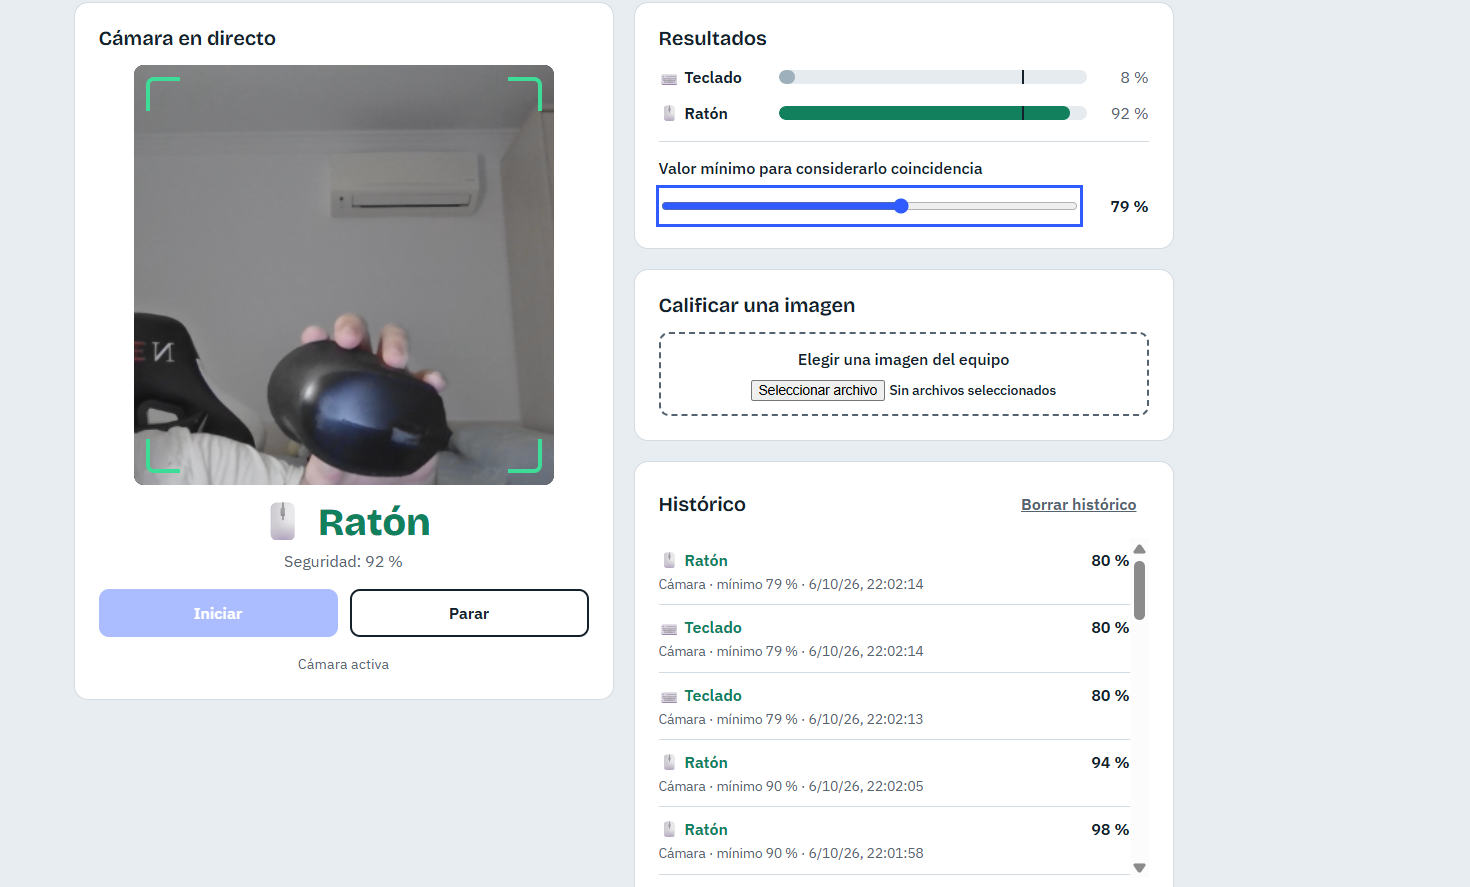

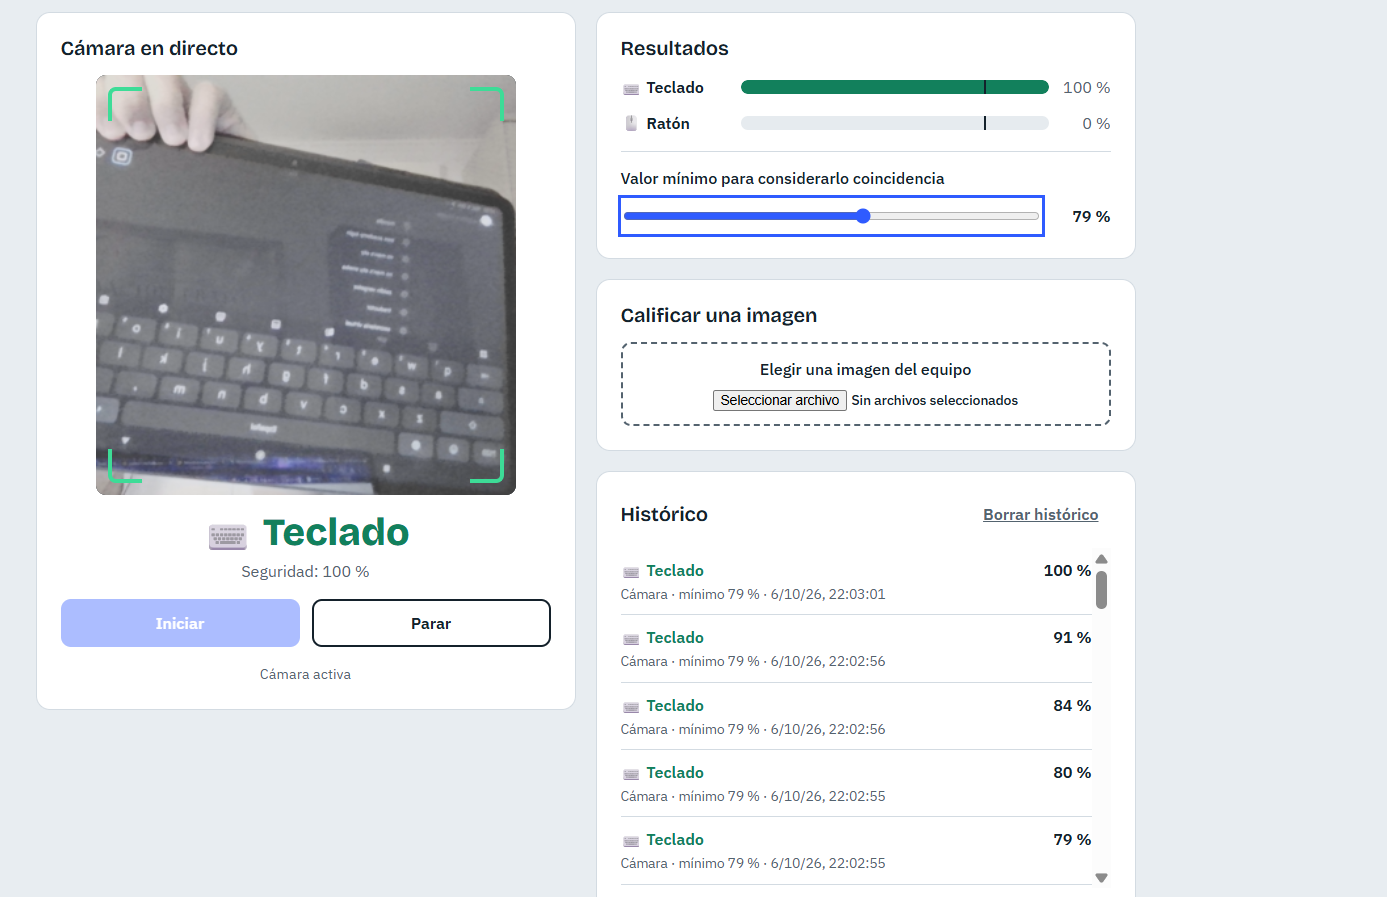

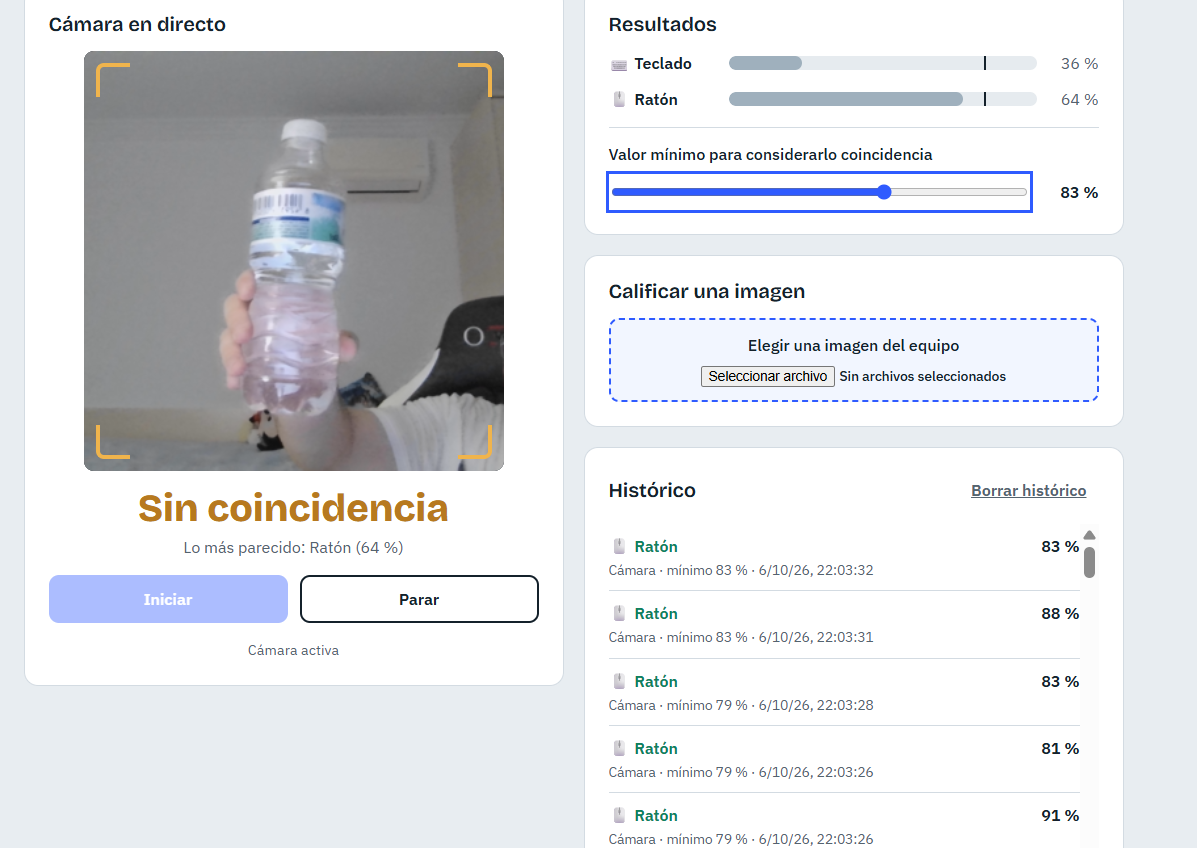